# PCA de las Gemínidas

Usaremos las tres componentes locales de velocidad residual de 2019–2024 para estudiar cómo varían los meteoros. Primero calculamos el PCA con todos los registros válidos; después comparamos los grupos de brillo sobre esos mismos ejes. El brillo no se usa para ajustar el PCA y 2025 queda fuera de este análisis.


In [1]:
# Bibliotecas utilizadas

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

## Cargar los datos de entrenamiento


In [2]:
# Localizar la carpeta principal del proyecto

ruta_actual = Path.cwd().resolve()

if (ruta_actual / "data").is_dir():
    raiz_proyecto = ruta_actual
elif (ruta_actual.parent / "data").is_dir():
    raiz_proyecto = ruta_actual.parent
else:
    raise FileNotFoundError("No se encontró la carpeta del proyecto.")

print("Raíz del proyecto:", raiz_proyecto)

Raíz del proyecto: C:\Users\pabpg\Documents\ignitia\Investigacion_geminidas


In [3]:
# Definir y comprobar la ruta de la base de entrenamiento

ruta_entrenamiento = (
    raiz_proyecto
    / "data"
    / "processed"
    / "geminidas_modelado_v2"
    / "geminidas_modelado_entrenamiento_2019_2024_v2.parquet"
)

if not ruta_entrenamiento.is_file():
    raise FileNotFoundError(
        f"No se encontró la base de entrenamiento: {ruta_entrenamiento}"
    )

print("Archivo encontrado:", ruta_entrenamiento.name)

Archivo encontrado: geminidas_modelado_entrenamiento_2019_2024_v2.parquet


In [4]:
# Cargar la base de entrenamiento sin modificar el archivo original

df_entrenamiento = pd.read_parquet(ruta_entrenamiento)

print("Filas y columnas:", df_entrenamiento.shape)
print("Años presentes:", sorted(df_entrenamiento["source_year"].unique()))

display(df_entrenamiento.head())

Filas y columnas: (12904, 39)
Años presentes: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


,id_fila_origen,Beginning (UTC Time),source_year,particion_modelado,pertenece_muestra_estricta,nivel_seleccion,fotometria_utilizable,Peak (AbsMag),magnitud_analisis,flag_fotometria_sospechosa,...,delta_v_beta_km_s,norma_delta_v_km_s,Qc (deg),MedianFitErr (arcsec),Participating (stations),numero_estaciones,sigma_radiante_aprox,Vgeo_sigma,flag_vgeo_sigma_cero,Vgeo_sigma_modelo
0,3068,2019-12-09 23:56:27.427184+00:00,2019,entrenamiento,False,Estándar no estricta,True,-0.26,-0.26,False,...,-0.836403,0.838669,32.52,48.76,"HR000N,HR0010,IT0001",3,0.243001,0.3589,False,0.3589
1,3183,2019-12-10 06:42:35.054618+00:00,2019,entrenamiento,False,Estándar no estricta,True,-0.11,-0.11,False,...,-0.546822,0.857829,64.52,49.37,"US0004,US0008,US000A",3,0.132314,0.1128,False,0.1128
2,3199,2019-12-10 07:22:06.203455+00:00,2019,entrenamiento,True,Estricta,True,-0.27,-0.27,False,...,0.577951,1.436028,83.93,45.18,"US0004,US0007,US0008,US000A,US000L",5,0.131344,0.0499,False,0.0499
3,3200,2019-12-10 07:24:37.501729+00:00,2019,entrenamiento,False,Estándar no estricta,True,-0.51,-0.51,False,...,0.056796,0.496120,52.84,19.83,"US000A,US000L",2,0.156847,0.0261,False,0.0261
4,3231,2019-12-10 08:55:32.942104+00:00,2019,entrenamiento,True,Estricta,True,-0.57,-0.57,False,...,0.523088,0.538091,56.52,54.92,"US0006,US0008,US000A,US000L",4,0.112714,0.1945,False,0.1945


## Revisar las variables que vamos a usar


In [5]:
# Tres componentes locales, todas en km/s

variables_pca = [
    "delta_v_paralela_km_s",
    "delta_v_lambda_km_s",
    "delta_v_beta_km_s"
]

# Comprobar que las variables existan
assert all(col in df_entrenamiento.columns for col in variables_pca)

# No mezclar 2025 aquí
assert df_entrenamiento["source_year"].between(2019, 2024).all()
assert (df_entrenamiento["particion_modelado"] == "entrenamiento").all()

# Cada trayectoria debe tener un ID único
assert not df_entrenamiento["id_fila_origen"].duplicated().any()

# Seleccionar las trayectorias utilizables para PCA
datos_pca = df_entrenamiento.loc[
    df_entrenamiento["usar_pca"], variables_pca
].copy()

# Comprobar que todos los valores sean numéricos y finitos
assert all(pd.api.types.is_numeric_dtype(datos_pca[col]) for col in variables_pca)
assert np.isfinite(datos_pca.to_numpy()).all()

print("Trayectorias utilizables:", len(datos_pca))
print("Variables del PCA:", len(variables_pca))

Trayectorias utilizables: 12904
Variables del PCA: 3


## Primer vistazo a las velocidades residuales


In [6]:
# Resumir las tres componentes antes de calcular el PCA

resumen_pca = datos_pca.describe().T

display(resumen_pca.round(4))

,count,mean,std,min,25%,50%,75%,max
delta_v_paralela_km_s,12904.0,-0.0015,0.6008,-3.4785,-0.3165,-0.0106,0.3096,3.4714
delta_v_lambda_km_s,12904.0,-0.0015,0.2302,-1.2455,-0.1297,0.0110,0.1385,1.1924
delta_v_beta_km_s,12904.0,-0.0001,0.2239,-1.1792,-0.1172,0.0072,0.1251,1.1088


## Centrado y matriz de covarianza


In [7]:
# Construir la matriz de las tres componentes de velocidad

X = datos_pca.to_numpy()

n = X.shape[0]

# Calcular el promedio de cada columna
media = X.mean(axis=0)

# Centrar los datos restando sus promedios
X_c = X - media

print("Dimensiones de X:", X.shape)
print("Medias:", media)
print("Medias después de centrar:", X_c.mean(axis=0))

Dimensiones de X: (12904, 3)
Medias: [-1.52257870e-03 -1.46689307e-03 -7.95433122e-05]
Medias después de centrar: [ 8.81020131e-18 -2.20255033e-18 -8.25956373e-19]


In [8]:
# Calcular la matriz de covarianza

S = (X_c.T @ X_c) / (n - 1)

tabla_covarianza = pd.DataFrame(
    S,
    index=variables_pca,
    columns=variables_pca
)

display(tabla_covarianza.round(5))

# Verificar que la matriz sea simétrica
assert np.allclose(S, S.T)

,delta_v_paralela_km_s,delta_v_lambda_km_s,delta_v_beta_km_s
delta_v_paralela_km_s,0.36097,-0.04805,-0.00774
delta_v_lambda_km_s,-0.04805,0.05301,0.01019
delta_v_beta_km_s,-0.00774,0.01019,0.05015


## Calcular el PCA


In [9]:
# Ajustar el PCA con las tres velocidades residuales de entrenamiento

pca = PCA(n_components=3)
pca.fit(X)

assert np.allclose(pca.mean_, media)
print("PCA ajustado con entrenamiento.")

PCA ajustado con entrenamiento.


In [10]:
# Obtener la varianza explicada por cada componente

tabla_varianza = pd.DataFrame({
    "Componente": ["PC1", "PC2", "PC3"],
    "Varianza": pca.explained_variance_,
    "Porcentaje (%)": 100 * pca.explained_variance_ratio_,
    "Acumulado (%)": 100 * np.cumsum(pca.explained_variance_ratio_)
})

display(tabla_varianza.round(4))

,Componente,Varianza,Porcentaje (%),Acumulado (%)
0,PC1,0.3686,79.4088,79.4088
1,PC2,0.0569,12.2666,91.6754
2,PC3,0.0386,8.3246,100.0000


In [11]:
# Comprobar que el PCA conserva la varianza total

varianza_original = np.trace(S)
varianza_pca = pca.explained_variance_.sum()

assert np.isclose(varianza_original, varianza_pca)
assert np.isclose(pca.explained_variance_ratio_.sum(), 1)

print("Varianza total original:", round(varianza_original, 6))
print("Varianza total en PCA:", round(varianza_pca, 6))
print("Verificación correcta.")

Varianza total original: 0.464123
Varianza total en PCA: 0.464123
Verificación correcta.


## Pesos de las componentes


In [12]:
# Obtener los pesos de cada componente principal

pesos_pca = pd.DataFrame(
    pca.components_.T,
    index=variables_pca,
    columns=["PC1", "PC2", "PC3"]
)

display(pesos_pca.round(4))

# Comprobar que los ejes principales sean ortonormales
assert np.allclose(
    pca.components_ @ pca.components_.T,
    np.eye(3)
)

print("Los tres ejes son ortonormales.")

,PC1,PC2,PC3
delta_v_paralela_km_s,0.9881,0.1164,0.1010
delta_v_lambda_km_s,-0.1514,0.6100,0.7778
delta_v_beta_km_s,-0.0289,0.7838,-0.6203


Los tres ejes son ortonormales.


## Obtener PC1, PC2 y PC3 para cada meteoro


In [13]:
# Pasar las velocidades a coordenadas PC1, PC2 y PC3

coordenadas_pca = pca.transform(X)

df_pca = pd.DataFrame(
    coordenadas_pca,
    columns=["PC1", "PC2", "PC3"],
    index=datos_pca.index
)

# Conservar el identificador para integrar las puntuaciones con otros notebooks
df_pca_por_id = df_pca.copy()
df_pca_por_id.insert(
    0, "id_fila_origen",
    df_entrenamiento.loc[datos_pca.index, "id_fila_origen"].to_numpy()
)
assert df_pca_por_id["id_fila_origen"].is_unique
assert np.allclose(coordenadas_pca, X_c @ pca.components_.T)

display(df_pca_por_id.head())
print("Dimensiones:", df_pca_por_id.shape)

,id_fila_origen,PC1,PC2,PC3
0,3068,0.026356,-0.616182,0.568395
1,3183,0.607866,-0.597683,0.097904
2,3199,-1.294421,0.612277,-0.097952
3,3200,0.478941,0.127236,0.046789
4,3231,-0.005443,0.489452,-0.224681


Dimensiones: (12904, 4)


In [14]:
# Comprobar las coordenadas y su matriz de covarianza

S_pca = np.cov(coordenadas_pca, rowvar=False)

display(pd.DataFrame(
    S_pca,
    index=["PC1", "PC2", "PC3"],
    columns=["PC1", "PC2", "PC3"]
).round(6))

# Verificar que las componentes no estén correlacionadas linealmente
assert np.allclose(
    S_pca,
    np.diag(pca.explained_variance_)
)

print("Covarianza verificada.")

,PC1,PC2,PC3
PC1,0.368554,0.000000,0.000000
PC2,0.000000,0.056932,-0.000000
PC3,0.000000,-0.000000,0.038636


Covarianza verificada.


## Cargas y mapa de correlaciones


In [15]:
# Calcular las correlaciones entre variables físicas y componentes principales

desviaciones = datos_pca.std(ddof=1).to_numpy()

cargas = (
    pca.components_.T
    * np.sqrt(pca.explained_variance_)
    / desviaciones[:, None]
)

tabla_cargas = pd.DataFrame(
    cargas,
    index=variables_pca,
    columns=["PC1", "PC2", "PC3"]
)

display(tabla_cargas.round(4))

# Comprobar que las correlaciones estén entre -1 y 1
assert np.abs(cargas).max() <= 1 + 1e-10

,PC1,PC2,PC3
delta_v_paralela_km_s,0.9984,0.0462,0.0331
delta_v_lambda_km_s,-0.3992,0.6322,0.6640
delta_v_beta_km_s,-0.0783,0.8351,-0.5445


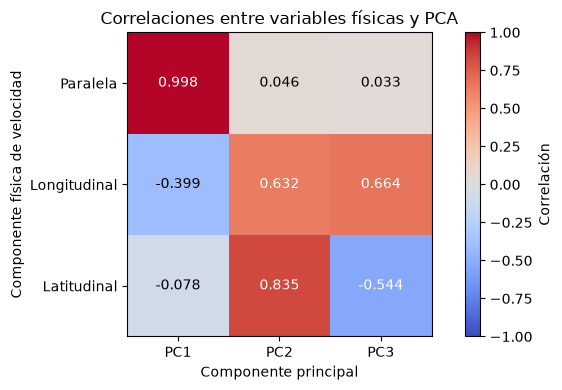

In [16]:
# Visualizar las correlaciones entre variables y componentes

fig, ax = plt.subplots(figsize=(7, 4))

mapa = ax.imshow(
    cargas,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(3), ["PC1", "PC2", "PC3"])

ax.set_yticks(
    range(3),
    ["Paralela", "Longitudinal", "Latitudinal"]
)

# Mostrar el valor numérico dentro de cada celda
for i in range(3):
    for j in range(3):
        ax.text(
            j, i, f"{cargas[i, j]:.3f}",
            ha="center",
            va="center",
            color="white" if abs(cargas[i, j]) > 0.5 else "black"
        )

barra = fig.colorbar(mapa, ax=ax)
barra.set_label("Correlación")

ax.set_xlabel("Componente principal")
ax.set_ylabel("Componente física de velocidad")
ax.set_title("Correlaciones entre variables físicas y PCA")

plt.tight_layout()
plt.show()

## Varianza explicada

El scree plot resume cuánta variación concentra cada componente. Como solo tenemos tres, no buscamos un «codo» a la fuerza.


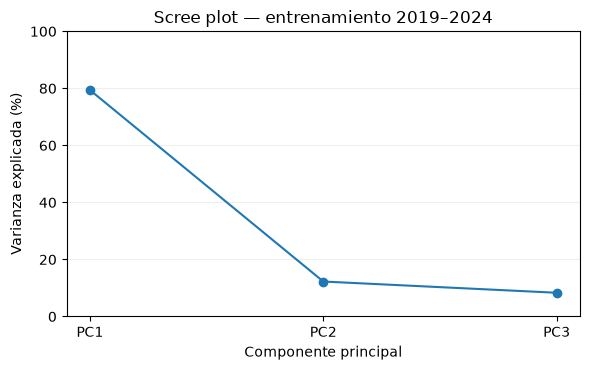

In [17]:
# Mostrar la varianza explicada sin repetir las tablas anteriores

fig, ax = plt.subplots(figsize=(6, 3.8))
porcentajes = 100 * pca.explained_variance_ratio_
ax.plot([1, 2, 3], porcentajes, marker="o", linewidth=1.5)
ax.set_xticks([1, 2, 3], ["PC1", "PC2", "PC3"])
ax.set_xlabel("Componente principal")
ax.set_ylabel("Varianza explicada (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.2)
ax.set_title("Scree plot — entrenamiento 2019–2024")
plt.tight_layout()
plt.show()

## Distribución de los meteoros en PC1 y PC2


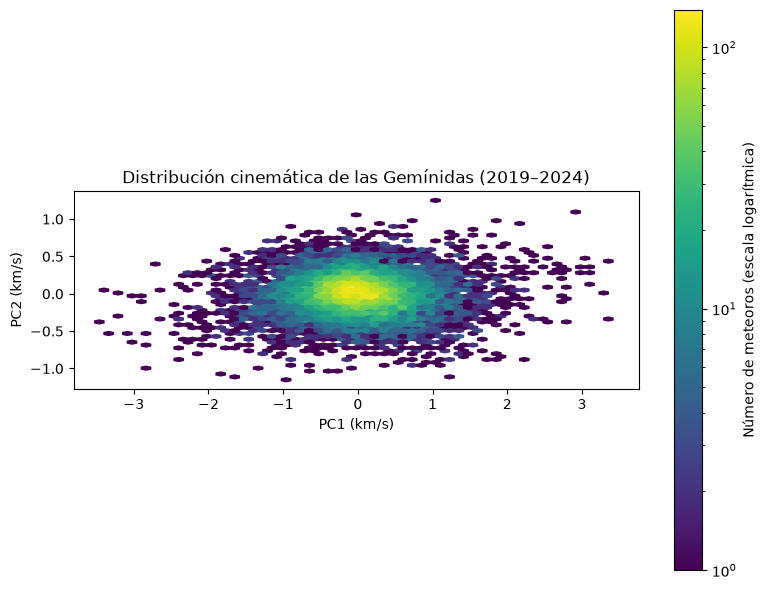

In [18]:
# Representar la concentración de meteoros en PC1 y PC2

fig, ax = plt.subplots(figsize=(8, 6))

mapa = ax.hexbin(
    df_pca["PC1"],
    df_pca["PC2"],
    gridsize=55,
    mincnt=1,
    bins="log",
    cmap="viridis"
)

barra = fig.colorbar(mapa, ax=ax)
barra.set_label("Número de meteoros (escala logarítmica)")

ax.set_xlabel("PC1 (km/s)")
ax.set_ylabel("PC2 (km/s)")
ax.set_title("Distribución cinemática de las Gemínidas (2019–2024)")

ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

## Biplot

Ponemos las cargas sobre la distribución de los meteoros. Las flechas son correlaciones ampliadas para poder verlas, así que **no están en km/s**.


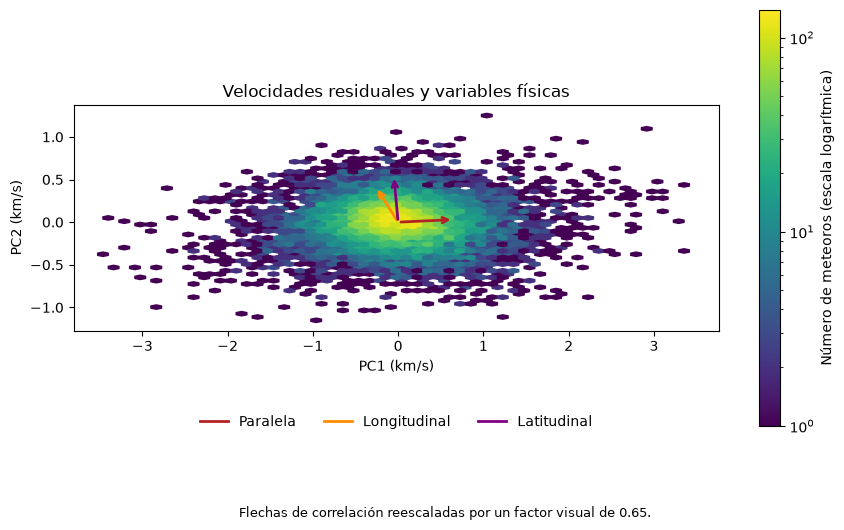

In [19]:
# Biplot: nube PC1-PC2 con las flechas de las variables originales

fig, ax = plt.subplots(figsize=(9, 5.3))
mapa = ax.hexbin(
    df_pca["PC1"], df_pca["PC2"],
    gridsize=55, mincnt=1, bins="log", cmap="viridis"
)

# Las correlaciones se reescalan solo para el dibujo
nombres = ["Paralela", "Longitudinal", "Latitudinal"]
colores = ["firebrick", "darkorange", "purple"]
escala_flechas = 0.65

for i, (nombre, color) in enumerate(zip(nombres, colores)):
    x = cargas[i, 0] * escala_flechas
    y = cargas[i, 1] * escala_flechas
    ax.annotate("", xy=(x, y), xytext=(0, 0),
                arrowprops={"arrowstyle": "->", "color": color, "lw": 2})
    ax.plot([], [], color=color, linewidth=2, label=nombre)

ax.set_xlabel("PC1 (km/s)")
ax.set_ylabel("PC2 (km/s)")
ax.set_aspect("equal", adjustable="box")
ax.set_title("Velocidades residuales y variables físicas")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32),
          ncol=3, frameon=False)
fig.colorbar(mapa, ax=ax, label="Número de meteoros (escala logarítmica)")
fig.text(0.5, 0.015, "Flechas de correlación reescaladas por un factor visual de 0.65.",
         ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.14, 1, 1])
plt.show()

## Comparar el PCA según el brillo

Los grupos se agregan después de ajustar el PCA. Así todos se comparan usando exactamente los mismos ejes.


In [20]:
# Incorporar el grupo de brillo de cada meteoro

df_analisis = df_pca.copy()

df_analisis["grupo_brillo"] = df_entrenamiento.loc[
    datos_pca.index, "grupo_brillo_ml"
]

# Revisar cuántos meteoros hay en cada grupo
print(df_analisis["grupo_brillo"].value_counts(dropna=False))

# Comparar medias y desviaciones estándar
resumen_grupos = df_analisis.groupby("grupo_brillo")[
    ["PC1", "PC2", "PC3"]
].agg(["mean", "std"])

display(resumen_grupos.round(4))

grupo_brillo
tenue         4332
brillante     4300
intermedio    4247
<NA>            25
Name: count, dtype: int64[pyarrow]


PC1             PC2             PC3        
                mean     std    mean     std    mean     std
grupo_brillo                                                
brillante     0.0949  0.4756  0.0213  0.2332  0.0152  0.1911
intermedio    0.0253  0.5504  0.0001  0.2293  0.0011  0.1894
tenue        -0.1193  0.7422 -0.0206  0.2509 -0.0160  0.2073

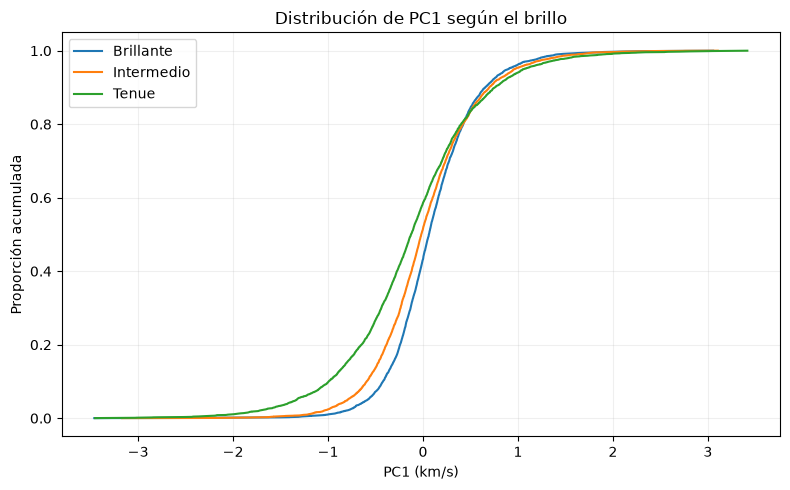

In [21]:
# Comparar las distribuciones acumuladas de PC1 según brillo

fig, ax = plt.subplots(figsize=(8, 5))

grupos = ["brillante", "intermedio", "tenue"]

for grupo in grupos:

    valores = df_analisis.loc[
        df_analisis["grupo_brillo"] == grupo, "PC1"
    ].sort_values().to_numpy()

    acumulada = np.arange(1, len(valores) + 1) / len(valores)

    ax.plot(valores, acumulada, label=grupo.capitalize())

ax.set_xlabel("PC1 (km/s)")
ax.set_ylabel("Proporción acumulada")
ax.set_title("Distribución de PC1 según el brillo")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Centros y dispersión por grupo


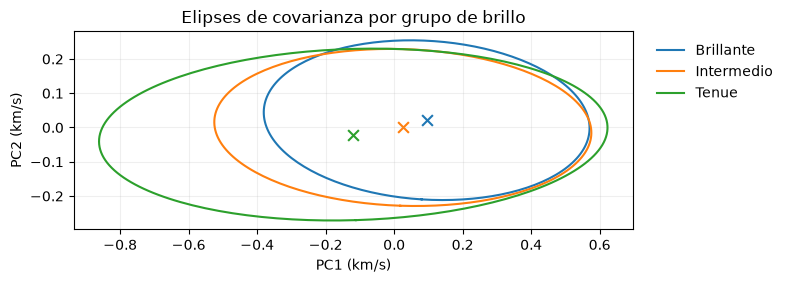

In [22]:
# Comparar centros y dispersiones de los grupos en PC1 y PC2

fig, ax = plt.subplots(figsize=(8, 5))

grupos = ["brillante", "intermedio", "tenue"]

angulos = np.linspace(0, 2 * np.pi, 200)
circulo = np.array([np.cos(angulos), np.sin(angulos)])

for grupo in grupos:

    datos = df_analisis.loc[
        df_analisis["grupo_brillo"] == grupo,
        ["PC1", "PC2"]
    ].to_numpy()

    # Centro y matriz de covarianza del grupo
    centro = datos.mean(axis=0)
    covarianza = np.cov(datos, rowvar=False)

    # Direcciones y varianzas principales del grupo
    valores, vectores = np.linalg.eigh(covarianza)

    # Construir la elipse de una desviación estándar
    elipse = centro[:, None] + vectores @ (
        np.sqrt(valores)[:, None] * circulo
    )

    linea, = ax.plot(
        elipse[0], elipse[1],
        label=grupo.capitalize()
    )

    ax.scatter(
        centro[0], centro[1],
        color=linea.get_color(),
        marker="x",
        s=60
    )

ax.set_xlabel("PC1 (km/s)")
ax.set_ylabel("PC2 (km/s)")
ax.set_title("Elipses de covarianza por grupo de brillo")
ax.set_aspect("equal", adjustable="box")
# Colocar la leyenda fuera del área de datos
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Dispersión usando las tres componentes


In [23]:
# Comparar la dispersión completa en los tres ejes del PCA global

componentes = ["PC1", "PC2", "PC3"]
grupos = ["brillante", "intermedio", "tenue"]

resultados = []

for grupo in grupos:

    datos_grupo = df_analisis.loc[
        df_analisis["grupo_brillo"] == grupo,
        componentes
    ]

    # Matriz de covarianza del grupo
    S_grupo = datos_grupo.cov()

    # Suma de las tres varianzas
    dispersion_total = np.trace(S_grupo.to_numpy())

    resultados.append({
        "Grupo": grupo,
        "Meteoros": len(datos_grupo),
        "Varianza PC1": S_grupo.loc["PC1", "PC1"],
        "Varianza PC2": S_grupo.loc["PC2", "PC2"],
        "Varianza PC3": S_grupo.loc["PC3", "PC3"],
        "Dispersión total": dispersion_total
    })

tabla_dispersion = pd.DataFrame(resultados)

display(tabla_dispersion.round(4))

,Grupo,Meteoros,Varianza PC1,Varianza PC2,Varianza PC3,Dispersión total
0,brillante,4300,0.2262,0.0544,0.0365,0.3171
1,intermedio,4247,0.3029,0.0526,0.0359,0.3913
2,tenue,4332,0.5509,0.0629,0.0430,0.6568


## Covarianzas y archivos de salida




In [24]:
# Las covarianzas se calculan por grupo, sin rehacer el PCA
componentes = ["PC1", "PC2", "PC3"]

for grupo in ["brillante", "intermedio", "tenue"]:
    datos_grupo = df_analisis.loc[
        df_analisis["grupo_brillo"] == grupo, componentes
    ]
    cov_grupo = datos_grupo.cov()

    assert len(datos_grupo) > 1
    assert np.allclose(cov_grupo, cov_grupo.T)
    assert np.linalg.eigvalsh(cov_grupo).min() >= -1e-10

    print(f"\n{grupo.capitalize()} — {len(datos_grupo)} meteoros")
    display(cov_grupo.round(5))



Brillante — 4300 meteoros


,PC1,PC2,PC3
PC1,0.22616,-0.01092,-0.00760
PC2,-0.01092,0.05437,-0.00336
PC3,-0.00760,-0.00336,0.03653



Intermedio — 4247 meteoros


,PC1,PC2,PC3
PC1,0.30290,-0.00855,-0.00750
PC2,-0.00855,0.05257,-0.00237
PC3,-0.00750,-0.00237,0.03588



Tenue — 4332 meteoros


,PC1,PC2,PC3
PC1,0.55085,0.01501,0.01173
PC2,0.01501,0.06293,0.00504
PC3,0.01173,0.00504,0.04297


In [25]:
# Guardar las puntuaciones y los parámetros del PCA de entrenamiento
ruta_tablas = raiz_proyecto / "reports" / "tables"
ruta_tablas.mkdir(parents=True, exist_ok=True)

ruta_puntuaciones = ruta_tablas / "pca_entrenamiento_2019_2024.parquet"
ruta_parametros = ruta_tablas / "pca_parametros_2019_2024.npz"

# Identificador para cruzar estos resultados con la base
assert df_pca_por_id["id_fila_origen"].is_unique
assert len(df_pca_por_id) == len(datos_pca)
assert df_entrenamiento["source_year"].between(2019, 2024).all()
df_pca_por_id.to_parquet(ruta_puntuaciones, index=False)

# Guardar la media y los ejes que aprendimos
np.savez_compressed(
    ruta_parametros,
    variables=np.array(variables_pca),
    media=pca.mean_,
    componentes=pca.components_,
    varianza=pca.explained_variance_,
    proporcion_varianza=pca.explained_variance_ratio_,
    anios_entrenamiento=np.arange(2019, 2025),
    unidades=np.array(["km/s", "km/s", "km/s"]),
)

# Comprobar que los archivos se puedan recuperar
puntuaciones_guardadas = pd.read_parquet(ruta_puntuaciones)
assert puntuaciones_guardadas["id_fila_origen"].equals(df_pca_por_id["id_fila_origen"].reset_index(drop=True))
assert np.allclose(puntuaciones_guardadas[["PC1", "PC2", "PC3"]], coordenadas_pca)
with np.load(ruta_parametros, allow_pickle=False) as parametros:
    puntuaciones_reconstruidas = (X - parametros["media"]) @ parametros["componentes"].T
    assert list(parametros["variables"]) == variables_pca
    assert np.allclose(puntuaciones_reconstruidas, coordenadas_pca)

print("Puntuaciones:", ruta_puntuaciones.relative_to(raiz_proyecto))
print("Parámetros:", ruta_parametros.relative_to(raiz_proyecto))
print("Comprobado: las proyecciones pueden reproducirse sin reajustar el PCA.")


Puntuaciones: reports\tables\pca_entrenamiento_2019_2024.parquet
Parámetros: reports\tables\pca_parametros_2019_2024.npz
Comprobado: las proyecciones pueden reproducirse sin reajustar el PCA.
